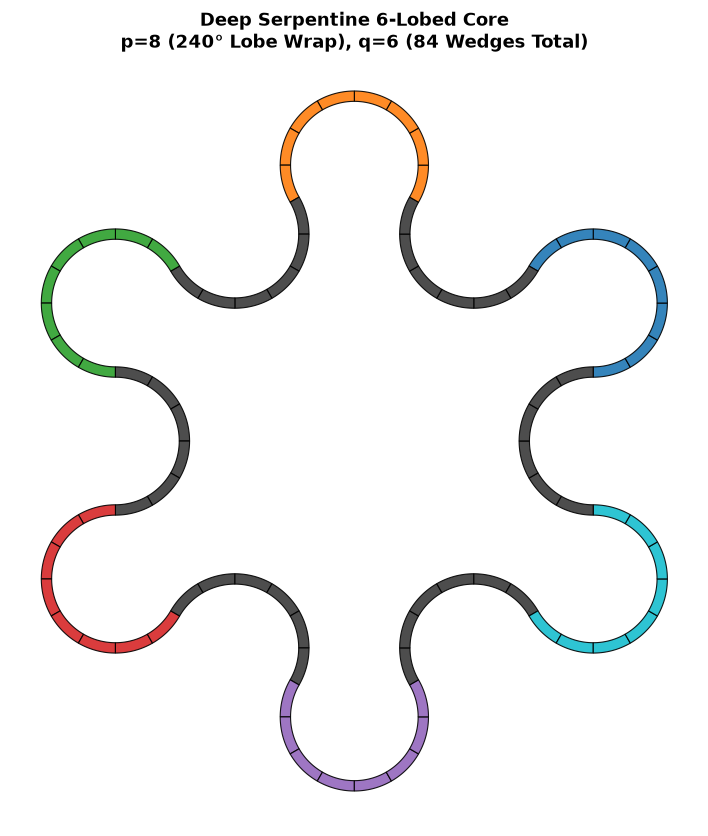

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

def plot_deep_enclosed_core(p=8, R0=1.0, thickness=0.18):
    """
    p=8: 240° convex wrap (8 convex, 6 concave per lobe -> 84 wedges total)
    p=9: 270° convex wrap (9 convex, 7 concave per lobe -> 96 wedges total)
    """
    q = p - 2
    one_lobe = [+1] * p + [-1] * q
    signs = one_lobe * 6
    arc_rad = np.radians(30.0)

    r_in = R0 - thickness / 2.0
    r_out = R0 + thickness / 2.0

    fig, ax = plt.subplots(figsize=(10, 10))
    x, y, heading = 0.0, 0.0, 0.0

    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#17becf']
    wedges_per_lobe = p + q

    for i, sgn in enumerate(signs):
        d_theta = sgn * arc_rad
        cx = x - sgn * R0 * np.sin(heading)
        cy = y + sgn * R0 * np.cos(heading)

        phi_start = np.arctan2(y - cy, x - cx)
        phi_end = phi_start + d_theta
        phi = np.linspace(phi_start, phi_end, 20)

        x_out = cx + r_out * np.cos(phi)
        y_out = cy + r_out * np.sin(phi)
        x_in  = cx + r_in * np.cos(phi[::-1])
        y_in  = cy + r_in * np.sin(phi[::-1])

        poly_pts = np.column_stack([
            np.concatenate([x_out, x_in]),
            np.concatenate([y_out, y_in])
        ])

        lobe_id = i // wedges_per_lobe
        col = colors[lobe_id] if sgn > 0 else '#3a3a3a'
        poly = Polygon(poly_pts, closed=True, facecolor=col, edgecolor='black', lw=0.8, alpha=0.9)
        ax.add_patch(poly)

        x = cx + R0 * np.cos(phi_end)
        y = cy + R0 * np.sin(phi_end)
        heading += d_theta

    ax.autoscale_view()
    ax.set_aspect('equal')
    ax.axis('off')
    plt.title(f"Deep Serpentine 6-Lobed Core\np={p} ({p*30}° Lobe Wrap), q={q} ({len(signs)} Wedges Total)", 
              fontsize=13, weight='bold')
    plt.show()

if __name__ == '__main__':
    # p=8 wraps 240° around each lobe (84 total wedges)
    # p=9 wraps 270° around each lobe like the ATR (96 total wedges)
    plot_deep_enclosed_core(p=8, thickness=0.15)

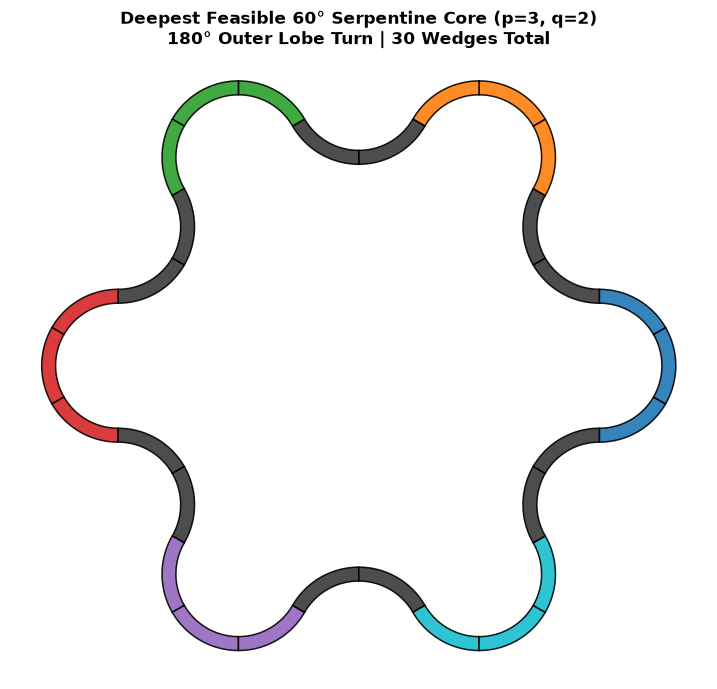

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

def plot_deepest_60deg_core(R0=1.0, thickness=0.20):
    # Deepest non-self-intersecting 60° configuration:
    # p = 3 convex (+60° each = 180° wrap)
    # q = 2 concave (-60° each = -120° return)
    # Total = 6 lobes * (3 + 2) = 30 wedges
    lobe_pattern = [+1, +1, +1, -1, -1]
    signs = lobe_pattern * 6
    arc_rad = np.radians(60.0)

    r_in = R0 - thickness / 2.0
    r_out = R0 + thickness / 2.0

    fig, ax = plt.subplots(figsize=(9, 9))
    x, y, heading = 0.0, 0.0, 0.0

    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#17becf']

    for i, sgn in enumerate(signs):
        d_theta = sgn * arc_rad

        # Center of curvature
        cx = x - sgn * R0 * np.sin(heading)
        cy = y + sgn * R0 * np.cos(heading)

        phi_start = np.arctan2(y - cy, x - cx)
        phi_end = phi_start + d_theta
        phi = np.linspace(phi_start, phi_end, 25)

        x_out = cx + r_out * np.cos(phi)
        y_out = cy + r_out * np.sin(phi)
        x_in  = cx + r_in * np.cos(phi[::-1])
        y_in  = cy + r_in * np.sin(phi[::-1])

        poly_pts = np.column_stack([
            np.concatenate([x_out, x_in]),
            np.concatenate([y_out, y_in])
        ])

        lobe_id = i // 5
        face_col = colors[lobe_id] if sgn > 0 else '#3a3a3a'
        poly = Polygon(poly_pts, closed=True, facecolor=face_col, 
                       edgecolor='black', lw=1.1, alpha=0.9)
        ax.add_patch(poly)

        x = cx + R0 * np.cos(phi_end)
        y = cy + R0 * np.sin(phi_end)
        heading += d_theta

    ax.autoscale_view()
    ax.set_aspect('equal')
    ax.axis('off')
    plt.title("Deepest Feasible 60° Serpentine Core (p=3, q=2)\n180° Outer Lobe Turn | 30 Wedges Total", 
              fontsize=12, weight='bold')
    plt.show()

if __name__ == '__main__':
    plot_deepest_60deg_core()

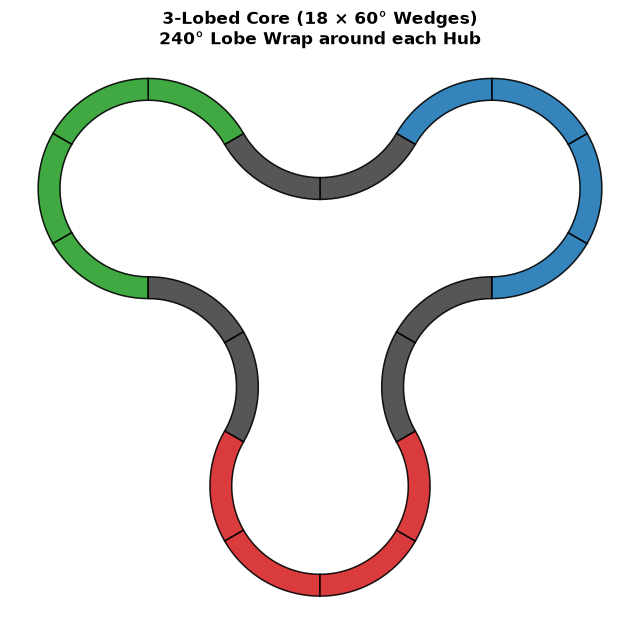

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

def plot_3lobe_core(wedge_deg=60, p=4, thickness=4.3416000000000015):
    """
    3-lobed core generator:
    - wedge_deg=60: requires p - q = 2 (e.g., p=4, q=2 -> 18 wedges total)
    - wedge_deg=30: requires p - q = 4 (e.g., p=9, q=5 -> 42 wedges total)
    """
    R0 = 4 + thickness / 2.0
    arc_rad = np.radians(wedge_deg)
    req_net_step = int(round(120.0 / wedge_deg))
    q = p - req_net_step
    assert q >= 0, f"p must be at least {req_net_step}"

    lobe_pattern = [+1] * p + [-1] * q
    signs = lobe_pattern * 3
    total_wedges = len(signs)

    r_in = R0 - thickness / 2.0
    r_out = R0 + thickness / 2.0

    fig, ax = plt.subplots(figsize=(8, 8))
    x, y, heading = 0.0, 0.0, 0.0

    colors = ['#1f77b4', '#2ca02c', '#d62728']
    wedges_per_lobe = p + q

    for i, sgn in enumerate(signs):
        d_theta = sgn * arc_rad
        cx = x - sgn * R0 * np.sin(heading)
        cy = y + sgn * R0 * np.cos(heading)

        phi_start = np.arctan2(y - cy, x - cx)
        phi_end = phi_start + d_theta
        phi = np.linspace(phi_start, phi_end, 20)

        x_out = cx + r_out * np.cos(phi)
        y_out = cy + r_out * np.sin(phi)
        x_in  = cx + r_in * np.cos(phi[::-1])
        y_in  = cy + r_in * np.sin(phi[::-1])

        poly_pts = np.column_stack([
            np.concatenate([x_out, x_in]),
            np.concatenate([y_out, y_in])
        ])

        lobe_id = i // wedges_per_lobe
        col = colors[lobe_id] if sgn > 0 else '#444444'
        poly = Polygon(poly_pts, closed=True, facecolor=col, edgecolor='black', lw=1.1, alpha=0.9)
        ax.add_patch(poly)

        x = cx + R0 * np.cos(phi_end)
        y = cy + R0 * np.sin(phi_end)
        heading += d_theta

    ax.autoscale_view()
    ax.set_aspect('equal')
    ax.axis('off')
    plt.title(f"3-Lobed Core ({total_wedges} × {wedge_deg}° Wedges)\n"
              f"{p * wedge_deg}° Lobe Wrap around each Hub", fontsize=12, weight='bold')
    plt.show()

if __name__ == '__main__':
    # 18 wedges total of 60°: 240° wrap around 3 lobes
    plot_3lobe_core(wedge_deg=60, p=4, thickness=0.22)
    
    # 42 wedges total of 30°: 270° wrap around 3 lobes (Uncomment to view)
    # plot_3lobe_core(wedge_deg=30, p=9, thickness=0.18)

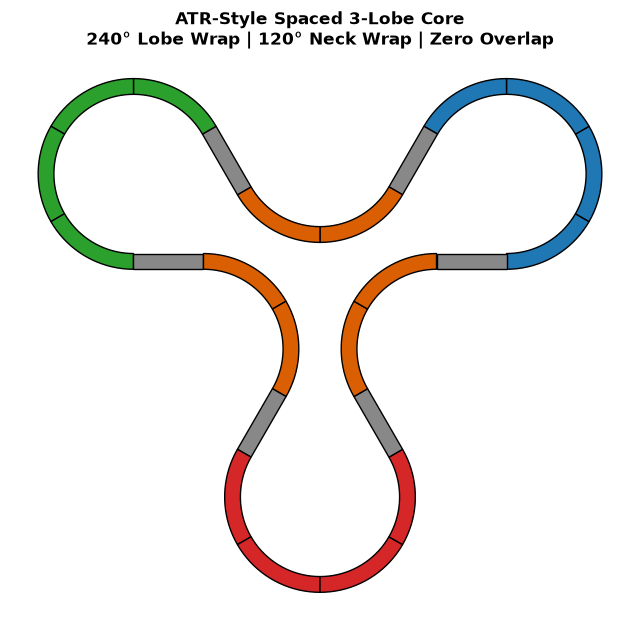

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

def plot_spaced_deep_core(R0=1.0, L_bridge=0.8, thickness=0.18):
    """
    3 Lobes: 4 convex (240°), 1 straight bridge, 2 concave (120°), 1 straight bridge.
    Guarantees deep wraparound with zero self-intersection.
    """
    arc_60 = np.radians(60.0)
    r_in = R0 - thickness / 2.0
    r_out = R0 + thickness / 2.0

    fig, ax = plt.subplots(figsize=(8, 8))
    x, y, heading = 0.0, 0.0, 0.0
    colors = ['#1f77b4', '#2ca02c', '#d62728']

    for lobe in range(3):
        # 1. Outer Lobe: 4 convex 60° wedges (240° wrap)
        for _ in range(4):
            cx = x - R0 * np.sin(heading)
            cy = y + R0 * np.cos(heading)
            phi_start = np.arctan2(y - cy, x - cx)
            phi_end = phi_start + arc_60
            phi = np.linspace(phi_start, phi_end, 20)
            
            x_out = cx + r_out * np.cos(phi)
            y_out = cy + r_out * np.sin(phi)
            x_in  = cx + r_in * np.cos(phi[::-1])
            y_in  = cy + r_in * np.sin(phi[::-1])
            
            poly = Polygon(np.column_stack([np.concatenate([x_out, x_in]),
                                           np.concatenate([y_out, y_in])]),
                           closed=True, facecolor=colors[lobe], edgecolor='black', lw=1)
            ax.add_patch(poly)
            x = cx + R0 * np.cos(phi_end)
            y = cy + R0 * np.sin(phi_end)
            heading += arc_60

        # 2. Tangent bridge to neck
        nx, ny = -np.sin(heading), np.cos(heading)
        p1 = [x + (thickness/2)*nx, y + (thickness/2)*ny]
        p2 = [x - (thickness/2)*nx, y - (thickness/2)*ny]
        x += L_bridge * np.cos(heading)
        y += L_bridge * np.sin(heading)
        p3 = [x - (thickness/2)*nx, y - (thickness/2)*ny]
        p4 = [x + (thickness/2)*nx, y + (thickness/2)*ny]
        ax.add_patch(Polygon([p1, p4, p3, p2], closed=True, facecolor='#888888', edgecolor='black', lw=1))

        # 3. Inner Neck: 2 concave 60° wedges (120° neck wrap)
        for _ in range(2):
            cx = x + R0 * np.sin(heading)
            cy = y - R0 * np.cos(heading)
            phi_start = np.arctan2(y - cy, x - cx)
            phi_end = phi_start - arc_60
            phi = np.linspace(phi_start, phi_end, 20)
            
            x_out = cx + r_in * np.cos(phi)
            y_out = cy + r_in * np.sin(phi)
            x_in  = cx + r_out * np.cos(phi[::-1])
            y_in  = cy + r_out * np.sin(phi[::-1])
            
            poly = Polygon(np.column_stack([np.concatenate([x_out, x_in]),
                                           np.concatenate([y_out, y_in])]),
                           closed=True, facecolor='#d95f02', edgecolor='black', lw=1)
            ax.add_patch(poly)
            x = cx + R0 * np.cos(phi_end)
            y = cy + R0 * np.sin(phi_end)
            heading -= arc_60

        # 4. Tangent bridge to next lobe
        nx, ny = -np.sin(heading), np.cos(heading)
        p1 = [x + (thickness/2)*nx, y + (thickness/2)*ny]
        p2 = [x - (thickness/2)*nx, y - (thickness/2)*ny]
        x += L_bridge * np.cos(heading)
        y += L_bridge * np.sin(heading)
        p3 = [x - (thickness/2)*nx, y - (thickness/2)*ny]
        p4 = [x + (thickness/2)*nx, y + (thickness/2)*ny]
        ax.add_patch(Polygon([p1, p4, p3, p2], closed=True, facecolor='#888888', edgecolor='black', lw=1))

    ax.autoscale_view()
    ax.set_aspect('equal')
    ax.axis('off')
    plt.title("ATR-Style Spaced 3-Lobe Core\n240° Lobe Wrap | 120° Neck Wrap | Zero Overlap", 
              fontsize=12, weight='bold')
    plt.show()

if __name__ == '__main__':
    plot_spaced_deep_core(R0=1.0, L_bridge=0.8, thickness=0.18)

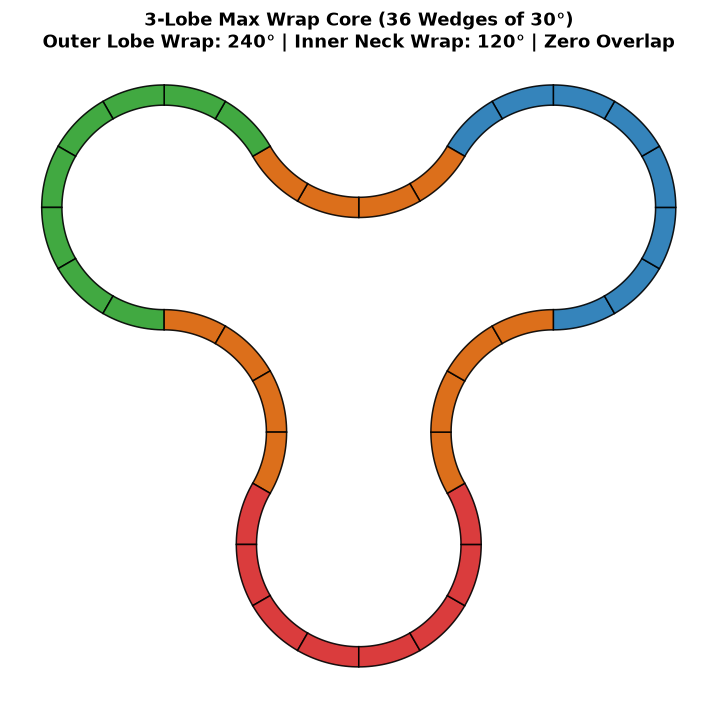

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Circle

def plot_3lobe_max_wrap(R0=12.4, thickness=0.18):
    p, q = 8, 4
    n_lobes = 3
    arc_deg = 30.0
    arc_rad = np.radians(arc_deg)

    r_in = R0 - thickness / 2.0
    r_out = R0 + thickness / 2.0

    signs = ([+1] * p + [-1] * q) * n_lobes
    total_wedges = len(signs)

    fig, ax = plt.subplots(figsize=(9, 9))
    x, y, heading = 0.0, 0.0, 0.0

    colors = ['#1f77b4', '#2ca02c', '#d62728']
    neck_color = '#d95f02'
    wedges_per_lobe = p + q

    for i, sgn in enumerate(signs):
        d_theta = sgn * arc_rad
        cx = x - sgn * R0 * np.sin(heading)
        cy = y + sgn * R0 * np.cos(heading)

        phi_start = np.arctan2(y - cy, x - cx)
        phi_end = phi_start + d_theta
        phi = np.linspace(phi_start, phi_end, 20)

        x_out = cx + r_out * np.cos(phi)
        y_out = cy + r_out * np.sin(phi)
        x_in  = cx + r_in * np.cos(phi[::-1])
        y_in  = cy + r_in * np.sin(phi[::-1])

        poly_pts = np.column_stack([
            np.concatenate([x_out, x_in]),
            np.concatenate([y_out, y_in])
        ])

        l_id = i // wedges_per_lobe
        col = colors[l_id] if sgn > 0 else neck_color
        ax.add_patch(Polygon(poly_pts, closed=True, facecolor=col,
                             edgecolor='black', lw=1.1, alpha=0.9))

        x = cx + R0 * np.cos(phi_end)
        y = cy + R0 * np.sin(phi_end)
        heading += d_theta

    ax.autoscale_view()
    ax.set_aspect('equal')
    ax.axis('off')
    plt.title(f"3-Lobe Max Wrap Core (36 Wedges of 30°)\n"
              f"Outer Lobe Wrap: 240° | Inner Neck Wrap: 120° | Zero Overlap",
              fontsize=13, weight='bold')
    plt.show()

if __name__ == '__main__':
    plot_3lobe_max_wrap(R0=1.0, thickness=0.18)